# 02 - ECAPA-TDNN Speaker Embeddings

## Objective

Extract a global speaker identity representation from VoxCeleb utterances using a pretrained ECAPA-TDNN model.

For an audio utterance $X$, we define:

$$
Z_{\mathrm{id}}(X)=E_{\mathrm{ECAPA}}(X).
$$

The ECAPA-TDNN encoder produces a 192-dimensional embedding representing speaker-related characteristics.

The first goal is to verify that the pretrained model can successfully produce an embedding for a single utterance.

We then evaluate whether the representation captures speaker identity by comparing cosine similarities between:

1. two utterances from the same speaker but different source videos;
2. two utterances from different speakers.

If the representation captures speaker identity, same-speaker similarities should be substantially larger than different-speaker similarities.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

print(Path.cwd())
print(PROJECT_ROOT)

/Users/juni/Documents/interview-anonymization/notebooks
/Users/juni/Documents/interview-anonymization


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import torch
import soundfile as sf
import random

In [3]:
METADATA_DIR = (
    Path.home()
    / "Documents"
    / "interview-anonymization"
    / "data"
    / "metadata"
)

utterance_df = pd.read_parquet(
    METADATA_DIR / "voxceleb_utterances.parquet"
)
wav_files = [Path(p) for p in utterance_df["path"]]

print("Number of wav files:", len(wav_files))

sample_path = wav_files[0]
print("Sample:", sample_path)

Number of wav files: 124843
Sample: /Users/juni/Documents/voxceleb1/wav/id10001/1zcIwhmdeo4/00001.wav


In [4]:
import soundfile as sf
import torch

audio, sample_rate = sf.read(sample_path)

waveform = torch.tensor(audio, dtype=torch.float32)

# Add channel dimension if mono
if waveform.ndim == 1:
    waveform = waveform.unsqueeze(0)

print("Waveform shape:", waveform.shape)
print("Sample rate:", sample_rate)

Waveform shape: torch.Size([1, 129921])
Sample rate: 16000


In [5]:
duration = waveform.shape[1] / sample_rate
print(duration)

8.1200625


In [6]:
from src.ecapa import load_ecapa, extract_embedding

classifier = load_ecapa()

In [7]:
with torch.no_grad():
    embedding = classifier.encode_batch(waveform)

In [8]:
print("Embedding shape:", embedding.shape)

Embedding shape: torch.Size([1, 1, 192])


In [9]:
z_id = embedding.squeeze()

print("Z_id shape:", z_id.shape)
print(z_id[:10])

Z_id shape: torch.Size([192])
tensor([ 20.0208,  17.0411, -24.6932,  11.5568, -15.3953,  15.6592,  -2.7259,
        -36.5680,  17.8046,   4.0380])


In [10]:
speaker_a = wav_files[0].parts[-3]

speaker_files = [
    p for p in wav_files
    if p.parts[-3] == speaker_a
]

videos = sorted(set(p.parts[-2] for p in speaker_files))

video1, video2 = videos[:2]

path_a1 = next(p for p in speaker_files if p.parts[-2] == video1)
path_a2 = next(p for p in speaker_files if p.parts[-2] == video2)

In [11]:
path_b = next(
    p for p in wav_files
    if p.parts[-3] != speaker_a
)

In [12]:
z_a1 = extract_embedding(path_a1, classifier)
z_a2 = extract_embedding(path_a2, classifier)
z_b = extract_embedding(path_b, classifier)

In [13]:
from torch.nn.functional import cosine_similarity

sim_same = cosine_similarity(
    z_a1.unsqueeze(0),
    z_a2.unsqueeze(0)
).item()

sim_diff = cosine_similarity(
    z_a1.unsqueeze(0),
    z_b.unsqueeze(0)
).item()

print("Same speaker similarity:", sim_same)
print("Different speaker similarity:", sim_diff)

Same speaker similarity: 0.6970235705375671
Different speaker similarity: 0.04030593857169151


## ECAPA embedding validation

To verify that the ECAPA-TDNN embeddings capture speaker identity,
we compare cosine similarities between:

1. two utterances from the same speaker but different source videos;
2. two utterances from different speakers.

If the representation captures speaker identity, same-speaker
similarities should be substantially larger than different-speaker
similarities.

In [17]:
import random
random.seed(42)

same_scores = []
diff_scores = []

speakers = sorted(set(p.parts[-3] for p in wav_files))

for _ in range(100):

    # -------------------------
    # Same speaker, different videos
    # -------------------------
    speaker = random.choice(speakers)

    speaker_files = [
        p for p in wav_files
        if p.parts[-3] == speaker
    ]

    videos = sorted(set(p.parts[-2] for p in speaker_files))

    if len(videos) >= 2:
        video1, video2 = random.sample(videos, 2)

        files_video1 = [
            p for p in speaker_files
            if p.parts[-2] == video1
        ]

        files_video2 = [
            p for p in speaker_files
            if p.parts[-2] == video2
        ]

        p1 = random.choice(files_video1)
        p2 = random.choice(files_video2)

        z1 = extract_embedding(p1, classifier)
        z2 = extract_embedding(p2, classifier)

        score = cosine_similarity(
            z1.unsqueeze(0),
            z2.unsqueeze(0)
        ).item()

        same_scores.append(score)

    # -------------------------
    # Different speakers
    # -------------------------
    speaker1, speaker2 = random.sample(speakers, 2)

    p1 = random.choice([
        p for p in wav_files
        if p.parts[-3] == speaker1
    ])

    p2 = random.choice([
        p for p in wav_files
        if p.parts[-3] == speaker2
    ])

    z1 = extract_embedding(p1, classifier)
    z2 = extract_embedding(p2, classifier)

    score = cosine_similarity(
        z1.unsqueeze(0),
        z2.unsqueeze(0)
    ).item()

    diff_scores.append(score)

In [18]:
import numpy as np

print("Mean same-speaker similarity:", np.mean(same_scores))
print("Mean different-speaker similarity:", np.mean(diff_scores))

Mean same-speaker similarity: 0.6159308072924614
Mean different-speaker similarity: 0.01096189328469336


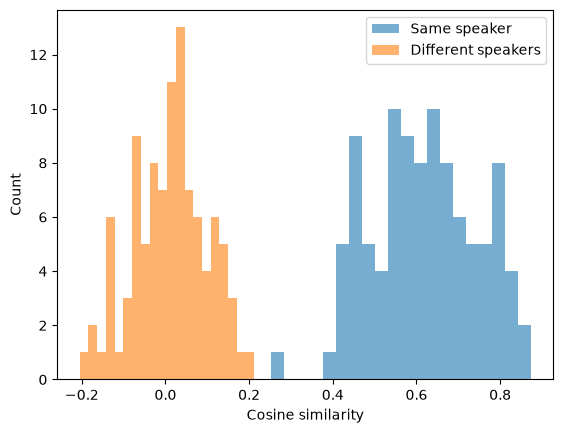

In [19]:
import matplotlib.pyplot as plt

plt.hist(same_scores, bins=20, alpha=0.6, label="Same speaker")
plt.hist(diff_scores, bins=20, alpha=0.6, label="Different speakers")

plt.xlabel("Cosine similarity")
plt.ylabel("Count")
plt.legend()
plt.show()

In [20]:
same_series = pd.Series(same_scores, name="Same speaker")
diff_series = pd.Series(diff_scores, name="Different speakers")

print("Same speaker:")
print(same_series.describe())

print("\nDifferent speakers:")
print(diff_series.describe())

Same speaker:
count    100.000000
mean       0.615931
std        0.128271
min        0.251728
25%        0.531644
50%        0.619523
75%        0.700324
max        0.872827
Name: Same speaker, dtype: float64

Different speakers:
count    100.000000
mean       0.010962
std        0.087996
min       -0.204881
25%       -0.054378
50%        0.019829
75%        0.068968
max        0.212640
Name: Different speakers, dtype: float64
